# Diamonds Price Prediction with Linear Regression

**Goal:** predict diamond prices (`price`, in USD) from physical and quality attributes.

**Dataset:** [Diamonds on Kaggle](https://www.kaggle.com/datasets/shivam2503/diamonds) (~54k rows).

## Data dictionary

| Column | Description |
|--------|-------------|
| `carat` | Weight of the diamond |
| `cut` | Cut quality: Fair < Good < Very Good < Premium < Ideal |
| `color` | Color grade from D (best) to J (worst) |
| `clarity` | Clarity grade: I1 (worst) < SI2 < SI1 < VS2 < VS1 < VVS2 < VVS1 < IF (best) |
| `depth` | Total depth percentage = z / mean(x, y) * 100 |
| `table` | Width of the top of the diamond relative to its widest point (%) |
| `price` | Price in US dollars (target variable) |
| `x` | Length in mm |
| `y` | Width in mm |
| `z` | Depth in mm |

`Unnamed: 0` is only a row index from the original CSV, so it is dropped.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load the data

In [2]:
dataset=pd.read_csv("data/diamonds.csv")
dataset=dataset.drop(columns=["Unnamed: 0"])
dataset.head(10)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
5,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
6,0.24,Very Good,I,VVS1,62.3,57.0,336,3.95,3.98,2.47
7,0.26,Very Good,H,SI1,61.9,55.0,337,4.07,4.11,2.53
8,0.22,Fair,E,VS2,65.1,61.0,337,3.87,3.78,2.49
9,0.23,Very Good,H,VS1,59.4,61.0,338,4.00,4.05,2.39


## 2. Initial inspection

The original file has 53,940 rows and 11 columns. After dropping `Unnamed: 0`,
10 columns remain: 3 categorical (`cut`, `color`, `clarity`) and 7 numeric.
There are no missing values.

In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


In [4]:
dataset.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


## 3. Missing values and duplicates

There are no missing values. After dropping `Unnamed: 0`, 146 duplicate rows are found.

In [5]:
print(dataset.isna().sum())

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64


In [6]:
print(dataset.duplicated().sum())

146


## 4. Data cleaning

### 4.1 Duplicate rows

The 146 duplicate rows are only about 0.3% of the data. The dataset has no ID column,
so they could be different stones with identical attributes. I removed them anyway,
because a duplicated row could end up in both the train and test sets and make the
test score look better than it really is.

Rows after removing duplicates: 53,794 (from 53,940).

In [7]:
print(dataset.shape)
dataset=dataset.drop_duplicates().reset_index(drop=True)
print(dataset.shape)

(53940, 10)
(53794, 10)


### 4.2 Invalid dimensions

The `describe()` output shows two problems in `x`, `y` and `z`:

- Some rows have a dimension equal to 0, which is physically impossible.
- `y` and `z` have extreme maximum values (58.9 mm and 31.8 mm) compared with their
  75th percentiles (6.54 mm and 4.04 mm).

The largest valid `x` is 10.74 mm, so only rows with all three dimensions between
1 mm and 11 mm were kept.

Rows after cleaning: 53,772 (22 rows removed).

In [8]:
dataset = dataset[
    dataset["x"].between(1, 11) &
    dataset["y"].between(1, 11) &
    dataset["z"].between(1, 11)
].reset_index(drop=True)
print(dataset.shape)

(53772, 10)


## 5. Exploratory data analysis

### 5.1 Price distribution

The distribution of `price` is strongly right-skewed. Almost half of the diamonds cost
less than about $2,000, and the number of stones falls steadily as the price increases,
with a long tail up to about $18,800. This skew is worth remembering when we look at
the residuals later.

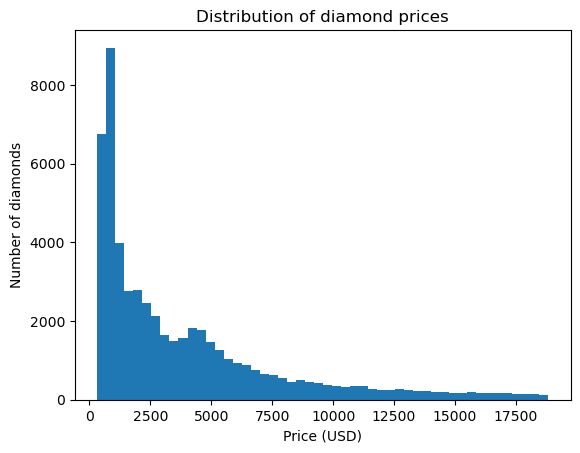

In [9]:
plt.hist(dataset['price'],bins=50)
plt.title('Distribution of diamond prices')
plt.xlabel('Price (USD)')
plt.ylabel('Number of diamonds')
plt.show()

### 5.2 Carat vs price

Price increases with carat, but the relationship is not a straight line: the curve bends
upward, and the spread of prices grows with carat (around 1 carat, prices range from
roughly $2,500 to over $15,000). Vertical stripes appear at round weights such as 1.0,
1.5 and 2.0 carat, because many stones are cut to round sizes. Prices also stop at about
$18,800, even for stones above 2 carat, so the data looks capped at the top.

A single straight line will not fit this pattern perfectly. We will check this with the
residual plot.

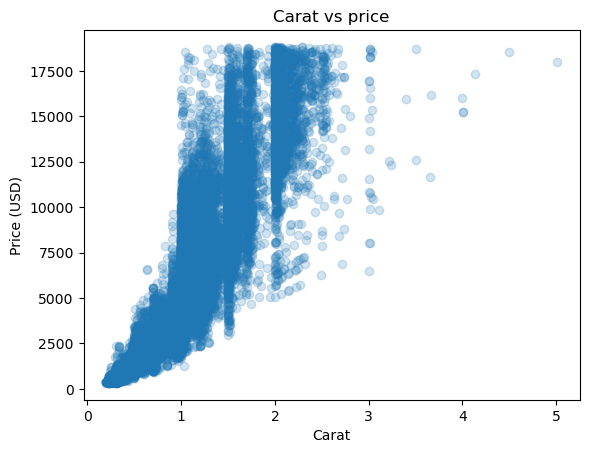

In [10]:
plt.scatter(dataset['carat'],dataset['price'],alpha=0.2)
plt.title('Carat vs price')
plt.xlabel('Carat')
plt.ylabel('Price (USD)')
plt.show()

### 5.3 Correlation between numeric features

- `price` is most strongly correlated with `carat` (0.92), followed by `x` and `y` (0.89)
  and `z` (0.88).
- `depth` (-0.01) and `table` (0.13) have almost no linear correlation with `price`.
- `carat`, `x`, `y` and `z` are almost perfectly correlated with each other (0.98 to 1.0).
  They all describe the size of the stone: a heavier diamond is larger in every dimension.

This is multicollinearity. A linear regression can still predict reasonably well, but the
coefficients of these features become unstable and hard to interpret, because the model
cannot tell which of them is responsible for the change in price.

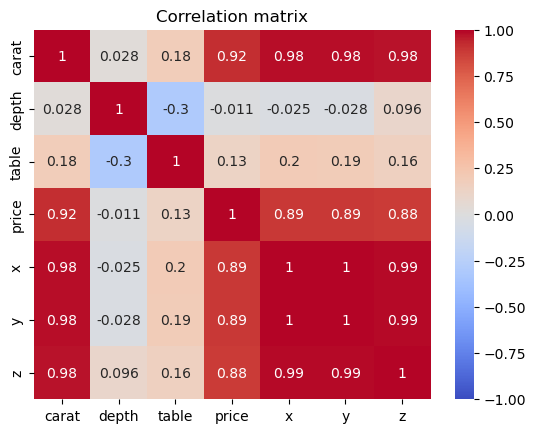

In [11]:
corr=dataset.corr(numeric_only=True)
sns.heatmap(corr,annot=True,cmap='coolwarm',vmax=1,vmin=-1)
plt.title('Correlation matrix')
plt.show()

## 6. Train/test split

The data is split 80/20 (`random_state=42`) before any encoding, so no information
from the test set leaks into the training process. The same split is used for both models.

In [12]:
X=dataset.drop(columns=['price'])
y=dataset['price']
print(X.shape)
print(y)

(53772, 9)
0         326
1         326
2         327
3         334
4         335
         ... 
53767    2757
53768    2757
53769    2757
53770    2757
53771    2757
Name: price, Length: 53772, dtype: int64


In [13]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(43017, 9)
(43017,)
(10755, 9)
(10755,)


## 7. Model A: one-hot encoding + linear regression

The categorical columns `cut`, `color` and `clarity` are one-hot encoded with
`drop='first'` to avoid the dummy variable trap. The numeric columns are passed through
unchanged. This gives 23 features: 17 dummy columns and 6 numeric columns. The encoder
is fitted on the training set only. Feature scaling is not needed for plain linear regression.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
ct=ColumnTransformer(transformers=[('encoder',OneHotEncoder(drop='first'),['cut','color','clarity'])],remainder='passthrough')
X_train_enc=ct.fit_transform(X_train)
X_test_enc=ct.transform(X_test)
print(X_test_enc.shape)
print(X_train_enc.shape)

(10755, 23)
(43017, 23)


In [15]:
from sklearn.linear_model import LinearRegression
regressor=LinearRegression()
regressor.fit(X_train_enc,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [16]:
y_pred=regressor.predict(X_test_enc)
y_pred_on_train=regressor.predict(X_train_enc)
pd.DataFrame({'Actual':y_test.values,'Predicted':y_pred}).head(10)

,Actual,Predicted
0,4039,4188.981148
1,3239,4092.070329
2,6090,5464.791182
3,7378,7117.739779
4,1212,1461.031277
5,6806,8133.367438
6,5714,6700.754278
7,1911,2572.019809
8,504,-1654.538012
9,1781,2017.271056


In [17]:
from sklearn.metrics import r2_score,mean_absolute_error,root_mean_squared_error
r2_test=r2_score(y_test,y_pred)
r2_train=r2_score(y_train,y_pred_on_train)
mae=mean_absolute_error(y_test,y_pred)
rmse=root_mean_squared_error(y_test,y_pred)
print(r2_test)
print(r2_train)
print(mae)
print(rmse)

0.9189781677927569
0.9210410805005922
726.5761077917804
1121.8496928890083


In [18]:
models=pd.DataFrame({'model_A':[r2_test,r2_train,mae,rmse]},index=['r2_test','r2_train','MAE','RMSE'])
models

,model_A
r2_test,0.918978
r2_train,0.921041
MAE,726.576108
RMSE,1121.849693


### 7.1 Results

| Metric | Value |
|--------|-------|
| R² (train) | 0.921 |
| R² (test) | 0.919 |
| MAE (test) | $726.58 |
| RMSE (test) | $1,121.85 |

The model explains about 92% of the variance in price. The train and test R² are almost
the same, so the model is not overfitting. On average, a prediction is off by about $727,
which is around 18% of the average price (about $3,930). The RMSE is larger than the MAE,
which means that some predictions have much larger errors than the rest.

The model also predicts negative prices for some cheap stones (for example, an actual
price of $504 was predicted as -$1,655). A linear regression has no lower bound, and a
straight line cannot follow the upward curve we saw in the carat vs price plot. We will
look at this more closely in the residual analysis.

## 8. Model B: ordinal encoding + linear regression

`cut`, `color` and `clarity` are ordered categories, so they are encoded as integers
that follow their quality order (a higher number means a better grade):
cut from Fair (0) to Ideal (4), color from J (0) to D (6), and clarity from I1 (0) to IF (7).
The numeric columns are passed through unchanged, which gives 9 features. The same
train/test split as in Model A is used.

In [19]:
from sklearn.preprocessing import OrdinalEncoder
ct_B = ColumnTransformer(
    transformers=[('encoder',
                   OrdinalEncoder(categories=[
                       ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal'],
                       ['J', 'I', 'H', 'G', 'F', 'E', 'D'],
                       ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']]),
                   ['cut', 'color', 'clarity'])],
    remainder='passthrough'
)
X_train_oe=ct_B.fit_transform(X_train)
X_test_oe=ct_B.transform(X_test)
print(X_train_oe.shape)
print(X_test_oe.shape)

(43017, 9)
(10755, 9)


In [20]:
regressor_B=LinearRegression()
regressor_B.fit(X_train_oe,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [21]:
y_pred_oe=regressor_B.predict(X_test_oe)
y_pred_on_train_oe=regressor_B.predict(X_train_oe)
pd.DataFrame({'Actual':y_test.values,'Predicted':y_pred_oe}).head(10)

,Actual,Predicted
0,4039,4123.845276
1,3239,4198.240039
2,6090,5424.267588
3,7378,6723.348695
4,1212,1414.234130
5,6806,8061.507399
6,5714,6643.620460
7,1911,2367.936472
8,504,-1308.605721
9,1781,1940.412171


In [22]:
r2_test_oe=r2_score(y_test,y_pred_oe)
r2_train_oe=r2_score(y_train,y_pred_on_train_oe)
mae_oe=mean_absolute_error(y_test,y_pred_oe)
rmse_oe=root_mean_squared_error(y_test,y_pred_oe)
print(r2_test_oe)
print(r2_train_oe)
print(mae_oe)
print(rmse_oe)

0.904839433775137
0.908894146189991
797.9082798782932
1215.800036689113


In [23]:
models['model_B'] = [r2_test_oe, r2_train_oe, mae_oe, rmse_oe]
models

,model_A,model_B
r2_test,0.918978,0.904839
r2_train,0.921041,0.908894
MAE,726.576108,797.908280
RMSE,1121.849693,1215.800037


## 9. Model comparison

| Metric | Model A (one-hot) | Model B (ordinal) |
|--------|-------------------|-------------------|
| R² (train) | 0.921 | 0.909 |
| R² (test) | 0.919 | 0.905 |
| MAE (test) | $726.58 | $797.91 |
| RMSE (test) | $1,121.85 | $1,215.80 |

Model A is better on all four metrics. Its average error is about $71 lower. Ordinal
encoding assumes that the price difference between two neighboring grades is always the
same, while one-hot encoding gives every grade its own effect, so it can describe the
data more closely. Neither model overfits: train and test R² are close for both.

Both models still predict negative prices for some cheap stones (for example, -$1,655 for
Model A and -$1,309 for Model B on a stone that actually costs $504).

## 10. Residual analysis (Model A)

The residual of a prediction is the actual price minus the predicted price. A positive
residual means that the model predicted too low, and a negative residual means that it
predicted too high. Model A is used here because it has the better test metrics.

### 10.1 Residuals vs predicted price

If a linear model fitted the data well, the residuals would form a random cloud around
zero with a constant width. This plot does not look like that:

- The cloud is wider for stones with a high predicted price than for cheap stones
  (funnel shape), so the errors of the model grow with the price.
- The residuals follow a curve. They are positive for the cheapest stones (the model
  predicted too low), close to zero or slightly negative for stones predicted between
  about $2,000 and $6,000, and often positive again between about $7,000 and $16,000
  (up to about +$8,000). This pattern means that the model misses the curve in the data.
- The few stones predicted above $20,000 all have large negative residuals, because the
  model predicted far too high for them. The worst one is about -$22,000.

### 10.2 Predicted vs actual price

For a perfect model all points would lie on the dashed line. Here the points follow the
line only in the middle of the range. For the cheapest stones many predictions fall below
the line and some are below zero. For stones above about $12,000 the predictions stay
mostly below the line and flatten out around $15,000, so the model underestimates
expensive stones. A few stones are strongly overestimated, with predictions up to about
$40,000 for stones that cost about $18,000.

### 10.3 Negative predictions

The model predicts 746 negative prices out of 10,755 test stones. All of them are cheap
stones (actual price below about $2,500).

### 10.4 Conclusion

A straight line explains about 92% of the variance in price, but the plots show that it
misses the curved relationship between the features and the price, makes larger errors
for expensive stones, and can predict impossible negative prices. A model that can capture
curves, or a transformation of the price (for example a logarithm), could improve the
results. These ideas are left for future work.

In [24]:
residuals_A=y_test-y_pred
print(residuals_A.head(10))

6388     -149.981148
2668     -853.070329
15107     625.208818
18142     260.260221
41161    -249.031277
16992   -1327.367438
14044    -986.754278
47718    -661.019809
41488    2158.538012
46401    -236.271056
Name: price, dtype: float64


In [25]:
n_neg = (y_pred < 0).sum()
print(n_neg)

746


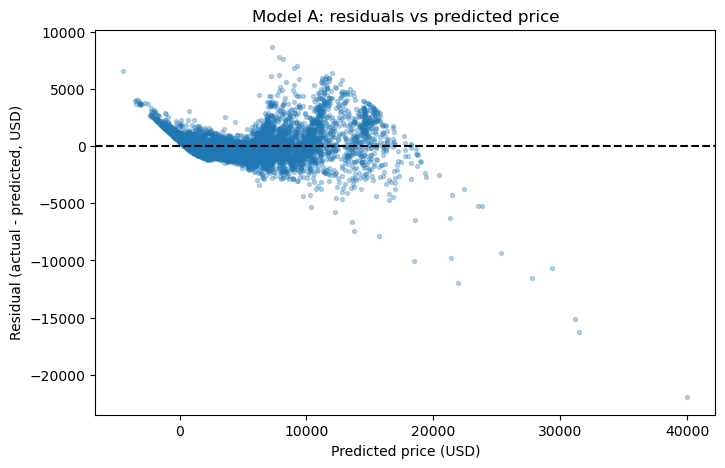

In [26]:
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals_A, alpha=0.3, s=8)
plt.axhline(0, color='black', linestyle='--')
plt.title('Model A: residuals vs predicted price')
plt.xlabel('Predicted price (USD)')
plt.ylabel('Residual (actual - predicted, USD)')
plt.show()

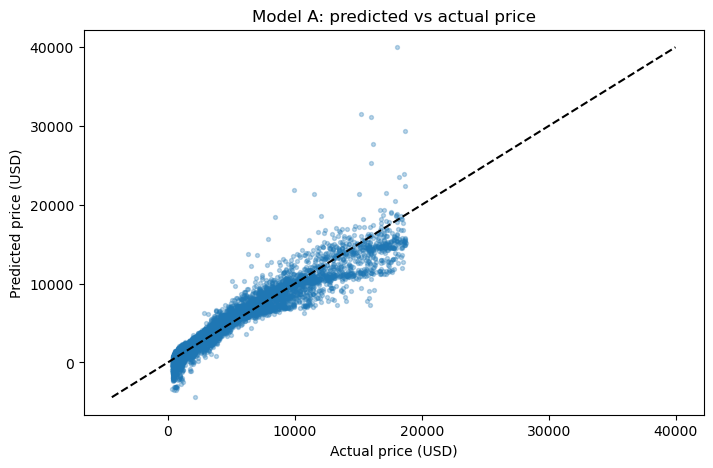

In [27]:
lo = min(y_test.min(), y_pred.min())
hi = max(y_test.max(), y_pred.max())
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.3, s=8)
plt.plot([lo, hi], [lo, hi], color='black', linestyle='--')
plt.title('Model A: predicted vs actual price')
plt.xlabel('Actual price (USD)')
plt.ylabel('Predicted price (USD)')
plt.show()